# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Naufal Fadhilah
- **Email:** ds322b6x1345@student.devacademy.id
- **ID Dicoding:** ds322b6x1345

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda harian (cnt) berdasarkan kombinasi musim dan kondisi cuaca selama periode 1 Januari 2011 hingga 31 Desember 2012, serta kombinasi mana yang memiliki rata-rata penyewaan tertinggi dan terendah untuk menentukan prioritas alokasi armada dan strategi promosi?
- **Pertanyaan 2:** Pada jam berapa rata-rata jumlah penyewaan sepeda per jam (cnt) mencapai tiga nilai tertinggi dan tiga nilai terendah selama periode 1 Januari 2011 hingga 31 Desember 2012, dan bagaimana hasil tersebut dapat digunakan untuk menentukan jadwal distribusi sepeda serta perawatan armada?

## Import Semua Packages/Library yang Digunakan

In [29]:
# Memanggil library yang diperlukan untuk analisis
import os
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tampilan visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)


## Data Wrangling

### Gathering Data

#### Load df ...

In [30]:
day_df = pd.read_csv('day.csv')
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [31]:
# Membaca dataset hour
hour_df = pd.read_csv('hour.csv')

# Menampilkan 5 baris pertama
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)

data day
- Dataset Bike Sharing berisi catatan jumlah penyewaan sepeda harian.
- Dataset memuat informasi waktu, kondisi cuaca, serta jumlah penyewaan oleh pengguna terdaftar dan pengguna kasual.

data hour
- Dataset hour_df memiliki informasi penyewaan sepeda berdasarkan jam.
- Dataset mencakup beberapa informasi, seperti tanggal, musim, bulan, jam penyewaan, kondisi cuaca, suhu, kelembapan, dan kecepatan angin.
- Terdapat kolom hr yang menunjukkan jam penyewaan sepeda, sehingga dataset dapat digunakan untuk menganalisis pola penyewaan berdasarkan waktu.
- Kolom casual menunjukkan jumlah pengguna kasual, sedangkan registered menunjukkan jumlah pengguna terdaftar.
- Kolom cnt menunjukkan total jumlah penyewaan sepeda setiap jam.

### Assessing Data

#### Identifying ... problem

In [32]:
# Memeriksa kondisi kedua dataset

datasets = {
    "day_df": day_df,
    "hour_df": hour_df
}

for nama, df in datasets.items():
    print(f"\n===== ASSESSING {nama.upper()} =====")

    # Informasi dataset dan tipe data
    print("\nInformasi dataset:")
    df.info()

    # Missing values
    print("\nMissing values:")
    print(df.isnull().sum())

    # Data duplikat
    print("\nJumlah data duplikat:")
    print(df.duplicated().sum())

    # Nilai penyewaan negatif
    print("\nJumlah nilai penyewaan negatif:")
    kolom_penyewaan = ["casual", "registered", "cnt"]
    print((df[kolom_penyewaan] < 0).sum())

    # Pemeriksaan kandidat outlier dengan metode IQR
    print("\nKandidat outlier:")
    kolom_numerik = [
        kolom for kolom in
        ["temp", "atemp", "hum", "windspeed",
         "casual", "registered", "cnt"]
        if kolom in df.columns
    ]

    for kolom in kolom_numerik:
        Q1 = df[kolom].quantile(0.25)
        Q3 = df[kolom].quantile(0.75)
        IQR = Q3 - Q1

        batas_bawah = Q1 - 1.5 * IQR
        batas_atas = Q3 + 1.5 * IQR

        jumlah_outlier = (
            (df[kolom] < batas_bawah) |
            (df[kolom] > batas_atas)
        ).sum()

        print(f"{kolom}: {jumlah_outlier}")



===== ASSESSING DAY_DF =====

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Missing values:
instant       0
dteday    

**Steps to Take:**

- Memperbaiki tipe data kolom dteday pada hour_df dari object menjadi datetime agar konsisten dengan day_df.
- Memeriksa konsistensi data penyewaan dengan memastikan nilai cnt sama dengan penjumlahan casual dan registered pada kedua dataset.
- Memeriksa validitas nilai pada kolom kategorikal, seperti season dan weathersit.
- Mempertahankan data yang teridentifikasi sebagai kandidat outlier selama nilainya masih masuk akal secara konteks, karena jumlah penyewaan yang tinggi dapat menunjukkan periode permintaan yang tinggi.
- Memastikan kedua dataset telah melalui pemeriksaan kualitas data yang sama sebelum digunakan dalam analisis lebih lanjut.



**Insight:** (Opsional)

- Dataset day_df memiliki 731 baris dan 16 kolom, sedangkan hour_df memiliki 17.379 baris dan 17 kolom.
- Kedua dataset tidak memiliki missing values maupun data duplikat.
- Tidak ditemukan nilai negatif pada kolom jumlah penyewaan (casual, registered, dan cnt).
- Ditemukan beberapa kandidat outlier pada kedua dataset, terutama pada kolom casual dan windspeed. Kandidat outlier tersebut perlu dievaluasi berdasarkan konteks data sebelum diputuskan untuk dihapus atau dipertahankan.
- Terdapat ketidakkonsistenan tipe data pada kolom dteday: bertipe datetime pada day_df, tetapi masih bertipe object pada hour_df.


### Cleaning Data

#### Fixing ... problem

In [33]:
# Mengubah tipe data dteday menjadi datetime
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# Memeriksa kembali tipe data
print("Tipe data dteday pada day_df:")
print(day_df["dteday"].dtype)

print("\nTipe data dteday pada hour_df:")
print(hour_df["dteday"].dtype)


Tipe data dteday pada day_df:
object

Tipe data dteday pada hour_df:
datetime64[ns]


In [34]:
# Memeriksa konsistensi jumlah penyewaan
for nama, df in {"day_df": day_df, "hour_df": hour_df}.items():
    print(f"\n===== {nama.upper()} =====")

    tidak_konsisten = (
        df["cnt"] != df["casual"] + df["registered"]
    ).sum()

    print("Jumlah data penyewaan tidak konsisten:", tidak_konsisten)

    print("Kategori season:", sorted(df["season"].unique()))
    print("Kategori weathersit:", sorted(df["weathersit"].unique()))

# Memeriksa rentang jam pada hour_df
print("\nKategori jam pada hour_df:")
print(sorted(hour_df["hr"].unique()))



===== DAY_DF =====
Jumlah data penyewaan tidak konsisten: 0
Kategori season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Kategori weathersit: [np.int64(1), np.int64(2), np.int64(3)]

===== HOUR_DF =====
Jumlah data penyewaan tidak konsisten: 0
Kategori season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Kategori weathersit: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Kategori jam pada hour_df:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]


In [35]:
# Membersihkan kedua dataset
for nama, df in {"day_df": day_df, "hour_df": hour_df}.items():
    jumlah_awal = len(df)

    # Memastikan tipe data tanggal
    df["dteday"] = pd.to_datetime(df["dteday"])

    # Menghapus duplikasi jika ditemukan
    df.drop_duplicates(inplace=True)

    # Menghapus baris dengan missing values jika ditemukan
    df.dropna(inplace=True)

    print(f"\n===== HASIL CLEANING {nama.upper()} =====")
    print("Jumlah data awal:", jumlah_awal)
    print("Jumlah data setelah cleaning:", len(df))
    print("Jumlah data yang dihapus:", jumlah_awal - len(df))
    print("Missing values tersisa:", df.isnull().sum().sum())
    print("Duplikasi tersisa:", df.duplicated().sum())



===== HASIL CLEANING DAY_DF =====
Jumlah data awal: 731
Jumlah data setelah cleaning: 731
Jumlah data yang dihapus: 0
Missing values tersisa: 0
Duplikasi tersisa: 0

===== HASIL CLEANING HOUR_DF =====
Jumlah data awal: 17379
Jumlah data setelah cleaning: 17379
Jumlah data yang dihapus: 0
Missing values tersisa: 0
Duplikasi tersisa: 0


**Insight:** (Opsional)
- Dataset day_df tetap memiliki 731 baris setelah proses pembersihan.
- Dataset hour_df tetap memiliki 17.379 baris setelah proses pembersihan.
- Tidak ada baris yang dihapus karena kedua dataset tidak memiliki missing values maupun data duplikat.
- Tipe data kolom dteday pada kedua dataset telah diseragamkan menjadi datetime.
- Kandidat outlier tetap dipertahankan karena nilai tersebut masih mungkin merepresentasikan kondisi penyewaan sepeda yang sebenarnya.

## Exploratory Data Analysis (EDA)

### Explore ...

In [36]:
# 1. Analisis Penyewaan Sepeda Berdasarkan Musim dan Kondisi Cuaca
# Rata-rata penyewaan sepeda berdasarkan musim
season_analysis = day_df.groupby("season").agg(
    rata_rata_penyewaan=("cnt", "mean"),
    total_penyewaan=("cnt", "sum")
).reset_index()

print("Analisis berdasarkan musim:")
display(season_analysis)

# Rata-rata penyewaan sepeda berdasarkan kondisi cuaca
weather_analysis = day_df.groupby("weathersit").agg(
    rata_rata_penyewaan=("cnt", "mean"),
    total_penyewaan=("cnt", "sum")
).reset_index()

print("\nAnalisis berdasarkan kondisi cuaca:")
display(weather_analysis)

# Hubungan musim dan kondisi cuaca dengan penyewaan
season_weather_analysis = day_df.pivot_table(
    values="cnt",
    index="season",
    columns="weathersit",
    aggfunc="mean"
)

print("\nRata-rata penyewaan berdasarkan musim dan cuaca:")
display(season_weather_analysis)


Analisis berdasarkan musim:


,season,rata_rata_penyewaan,total_penyewaan
0,1,2604.132597,471348
1,2,4992.331522,918589
2,3,5644.303191,1061129
3,4,4728.162921,841613



Analisis berdasarkan kondisi cuaca:


,weathersit,rata_rata_penyewaan,total_penyewaan
0,1,4876.786177,2257952
1,2,4035.862348,996858
2,3,1803.285714,37869



Rata-rata penyewaan berdasarkan musim dan cuaca:


weathersit,1,2,3
season,,,
1,2811.135135,2357.166667,934.75
2,5548.548673,4236.705882,1169.00
3,5878.257353,5222.479167,2751.75
4,5043.563107,4654.000000,1961.60


In [37]:
# 2. Analisis Pola Penyewaan Sepeda Berdasarkan Jam dan Kondisi Cuaca

# Rata-rata penyewaan berdasarkan jam
hour_analysis = hour_df.groupby("hr").agg(
    rata_rata_penyewaan=("cnt", "mean"),
    total_penyewaan=("cnt", "sum")
).reset_index()

print("Analisis penyewaan berdasarkan jam:")
display(hour_analysis)

# Rata-rata penyewaan berdasarkan jam dan kondisi cuaca
hour_weather_analysis = hour_df.pivot_table(
    values="cnt",
    index="hr",
    columns="weathersit",
    aggfunc="mean"
)

print("\nAnalisis penyewaan berdasarkan jam dan kondisi cuaca:")
display(hour_weather_analysis)

# Menentukan jam dengan rata-rata penyewaan tertinggi dan terendah
jam_tertinggi = hour_analysis.loc[
    hour_analysis["rata_rata_penyewaan"].idxmax()
]

jam_terendah = hour_analysis.loc[
    hour_analysis["rata_rata_penyewaan"].idxmin()
]

print("\nJam dengan penyewaan tertinggi:")
display(jam_tertinggi)

print("\nJam dengan penyewaan terendah:")
display(jam_terendah)


Analisis penyewaan berdasarkan jam:


,hr,rata_rata_penyewaan,total_penyewaan
0,0,53.898072,39130
1,1,33.375691,24164
2,2,22.869930,16352
3,3,11.727403,8174
4,4,6.352941,4428
5,5,19.889819,14261
6,6,76.044138,55132
7,7,212.064649,154171
8,8,359.011004,261001
9,9,219.309491,159438



Analisis penyewaan berdasarkan jam dan kondisi cuaca:


weathersit,1,2,3,4
hr,,,,
0,59.161554,47.232432,28.115385,NaN
1,34.395918,35.541899,17.129630,23.0
2,22.817992,25.491713,14.839286,NaN
3,11.995604,12.452128,6.944444,NaN
4,6.413567,6.721311,4.684211,NaN
5,20.414687,20.141463,13.877551,NaN
6,79.165563,74.612903,55.981818,NaN
7,218.742664,224.733645,131.071429,NaN
8,361.359091,391.283843,213.775862,NaN



Jam dengan penyewaan tertinggi:


,17
hr,17.000000
rata_rata_penyewaan,461.452055
total_penyewaan,336860.000000



Jam dengan penyewaan terendah:


,4
hr,4.000000
rata_rata_penyewaan,6.352941
total_penyewaan,4428.000000


**Insight:** (Opsional)

Berdasarkan hasil eksplorasi data berdasarkan hari, diperoleh beberapa temuan:
- Musim gugur (season 3) merupakan musim dengan rata-rata penyewaan sepeda tertinggi, yaitu sekitar 5.644 penyewaan per hari. Sebaliknya, musim semi (season 1) memiliki rata-rata terendah, yaitu sekitar 2.604 penyewaan per hari.
- Kondisi cuaca berpengaruh terhadap pola penyewaan. Cuaca cerah (weathersit 1) memiliki rata-rata penyewaan tertinggi sebesar 4.877, sedangkan cuaca buruk (weathersit 3) hanya sekitar 1.803 penyewaan.
- Hasil pengelompokan berdasarkan kombinasi musim dan cuaca menunjukkan bahwa rata-rata penyewaan tertinggi terjadi pada musim gugur dengan cuaca cerah, yaitu sekitar 5.878 penyewaan.
- Pola tersebut menunjukkan bahwa musim dan kondisi cuaca perlu dipertimbangkan dalam perencanaan ketersediaan armada dan strategi promosi.

Berdasarkan hasil eksplorasi pola penyewaan berdasarkan jam dan kondisi cuaca, diperoleh beberapa temuan:
- Jam 17.00 merupakan waktu dengan rata-rata penyewaan tertinggi, yaitu sekitar 461 sepeda per jam. Jam 18.00 juga menunjukkan permintaan tinggi dengan rata-rata sekitar 426 sepeda per jam.
- Jam 04.00 merupakan waktu dengan rata-rata penyewaan terendah, yaitu sekitar 6 sepeda per jam.
- Pola penyewaan menunjukkan peningkatan pada pagi hari, terutama pukul 07.00–08.00, serta sore hari pada pukul 16.00–18.00.
- Kondisi cuaca juga berkaitan dengan pola penyewaan. Pada sebagian besar jam, rata-rata penyewaan saat cuaca cerah lebih tinggi dibandingkan saat cuaca buruk.
- Pada pukul 17.00, rata-rata penyewaan saat cuaca cerah mencapai sekitar 500 sepeda, sedangkan saat cuaca buruk sekitar 276 sepeda.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

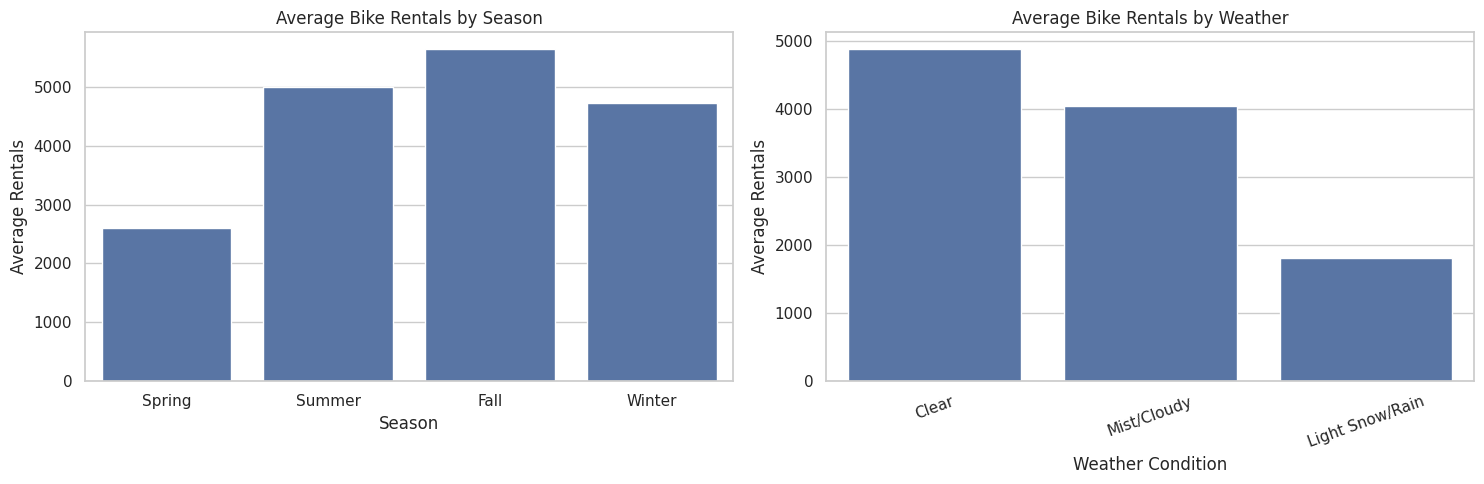

In [38]:
## 1. Pengaruh Musim dan Kondisi Cuaca terhadap Penyewaan Sepeda

import matplotlib.pyplot as plt
import seaborn as sns

# Nama kategori musim dan cuaca
season_labels = {
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
}

weather_labels = {
    1: "Clear",
    2: "Mist/Cloudy",
    3: "Light Snow/Rain",
    4: "Heavy Rain"
}

# Menyiapkan data visualisasi
season_plot = day_df.groupby("season")["cnt"].mean().reset_index()
season_plot["season_name"] = season_plot["season"].map(season_labels)

weather_plot = day_df.groupby("weathersit")["cnt"].mean().reset_index()
weather_plot["weather_name"] = weather_plot["weathersit"].map(weather_labels)

# Membuat dua grafik
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=season_plot,
    x="season_name",
    y="cnt",
    ax=axes[0]
)
axes[0].set_title("Average Bike Rentals by Season")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Average Rentals")

sns.barplot(
    data=weather_plot,
    x="weather_name",
    y="cnt",
    ax=axes[1]
)
axes[1].set_title("Average Bike Rentals by Weather")
axes[1].set_xlabel("Weather Condition")
axes[1].set_ylabel("Average Rentals")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


### Explanatory Analysis – Pertanyaan Bisnis 1

Berdasarkan visualisasi, jumlah penyewaan sepeda tertinggi terjadi pada musim gugur (Fall), sedangkan jumlah terendah terjadi pada musim semi (Spring). Kondisi cuaca juga menunjukkan pengaruh terhadap penyewaan sepeda. Cuaca cerah memiliki rata-rata penyewaan tertinggi, sementara kondisi cuaca buruk memiliki rata-rata penyewaan lebih rendah.

Hasil ini menunjukkan bahwa musim dan kondisi cuaca dapat menjadi pertimbangan dalam menentukan strategi bisnis. Penyedia layanan dapat mengoptimalkan ketersediaan armada pada musim dengan permintaan tinggi serta menjalankan promosi pada musim dengan permintaan lebih rendah. Promosi juga dapat difokuskan pada hari-hari dengan kondisi cuaca yang mendukung aktivitas bersepeda.

### Pertanyaan 2:

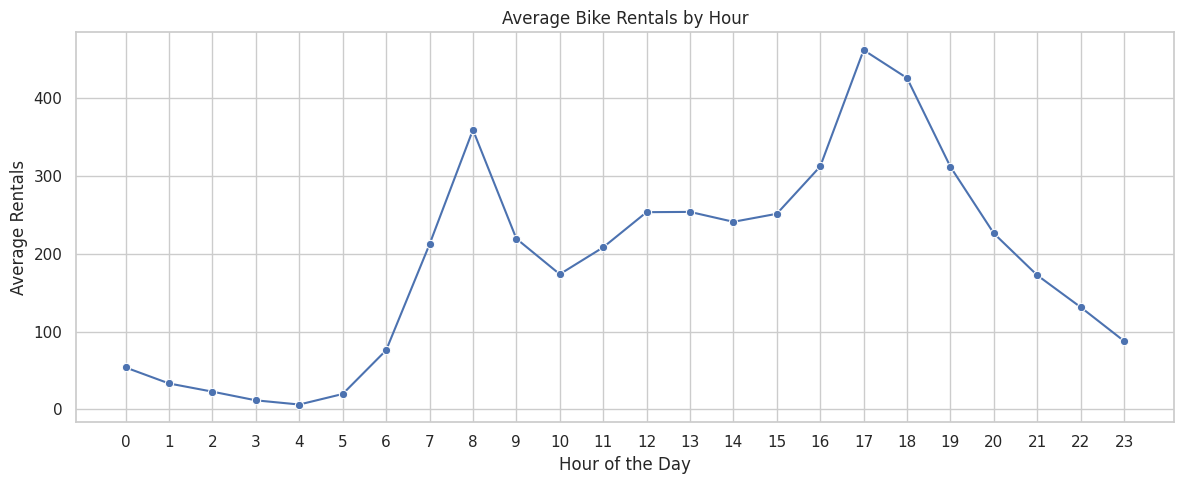

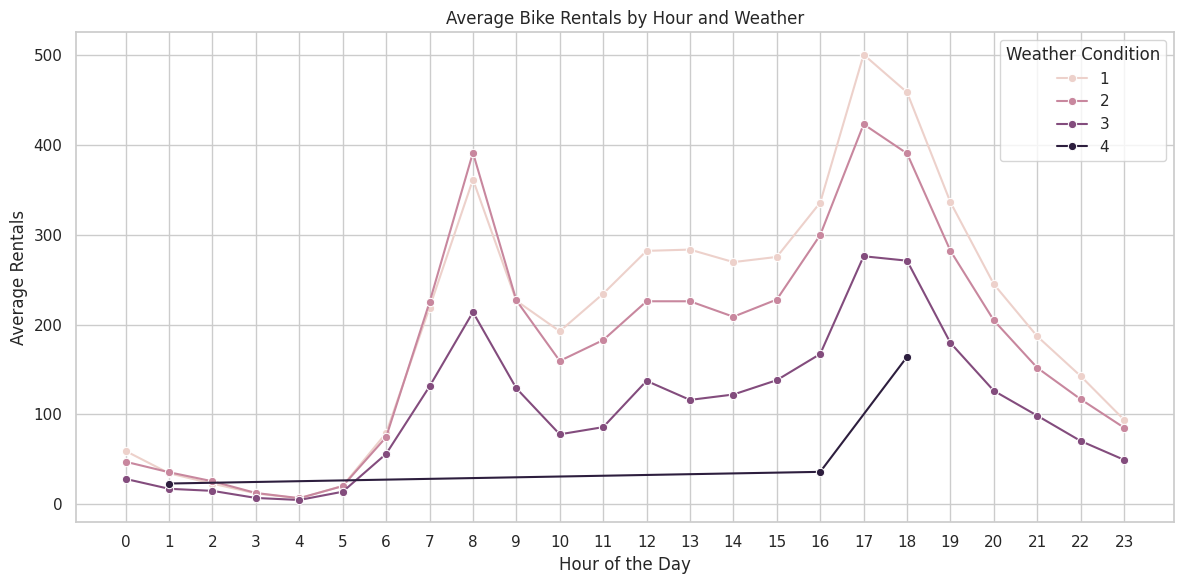

In [39]:
## 2. Pola Penyewaan Sepeda Berdasarkan Jam dan Kondisi Cuaca
# Menghitung rata-rata penyewaan berdasarkan jam
hour_plot = hour_df.groupby("hr")["cnt"].mean().reset_index()

# Grafik rata-rata penyewaan berdasarkan jam
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hour_plot,
    x="hr",
    y="cnt",
    marker="o"
)

plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Rentals")
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

# Grafik pola penyewaan berdasarkan jam dan cuaca
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hour_df,
    x="hr",
    y="cnt",
    hue="weathersit",
    estimator="mean",
    errorbar=None,
    marker="o"
)

plt.title("Average Bike Rentals by Hour and Weather")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Rentals")
plt.xticks(range(24))
plt.legend(title="Weather Condition")
plt.grid(True)
plt.tight_layout()
plt.show()


### Explanatory Analysis – Pertanyaan Bisnis 2

Berdasarkan visualisasi, permintaan penyewaan sepeda paling tinggi terjadi pada pukul 17.00, disusul pukul 18.00 dan 08.00. Sementara itu, permintaan paling rendah terjadi pada pukul 04.00. Pola ini menunjukkan bahwa penyewaan sepeda cenderung meningkat pada jam-jam aktivitas masyarakat, terutama pagi dan sore hari.

Kondisi cuaca juga berkaitan dengan jumlah penyewaan pada setiap jam. Secara umum, penyewaan lebih tinggi ketika cuaca cerah dibandingkan ketika cuaca kurang mendukung.

Informasi ini dapat digunakan untuk mengatur distribusi sepeda agar lebih banyak tersedia pada jam sibuk, khususnya pukul 07.00–09.00 dan 16.00–18.00. Pada jam dengan permintaan rendah, penyedia layanan dapat menjadwalkan perawatan armada agar operasional lebih efisien.

**Insight:** (Opsional)

- Pengaruh musim: Musim gugur (Fall) memiliki rata-rata penyewaan tertinggi, sedangkan musim semi (Spring) memiliki rata-rata penyewaan terendah. Hal ini menunjukkan adanya perbedaan permintaan penyewaan berdasarkan musim.
- Pengaruh cuaca: Cuaca cerah (Clear) menghasilkan rata-rata penyewaan tertinggi. Sebaliknya, kondisi cuaca buruk memiliki rata-rata penyewaan yang lebih rendah.
- Pola penyewaan berdasarkan jam: Permintaan penyewaan meningkat pada pagi hari, khususnya pukul 07.00–08.00, dan mencapai puncak pada pukul 17.00. Permintaan paling rendah terjadi pada pukul 04.00.
- Hubungan jam dan cuaca: Pada sebagian besar jam, rata-rata penyewaan ketika cuaca cerah lebih tinggi dibandingkan ketika cuaca buruk. Perbedaan tersebut terlihat jelas pada jam sibuk, terutama pukul 17.00.
- Implikasi bisnis: Pengelola dapat meningkatkan ketersediaan sepeda pada jam sibuk dan musim dengan permintaan tinggi. Selain itu, strategi promosi dapat diarahkan pada musim dan periode dengan permintaan rendah untuk meningkatkan jumlah penyewaan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:**

Berdasarkan analisis dataset harian (day_df), musim dan kondisi cuaca menunjukkan hubungan dengan jumlah penyewaan sepeda.
Musim gugur (Fall) memiliki rata-rata penyewaan tertinggi sebesar 5.644 sepeda per hari, sedangkan musim semi (Spring) memiliki rata-rata terendah sebesar 2.604 sepeda per hari.
Berdasarkan kondisi cuaca, cuaca cerah (Clear) memiliki rata-rata penyewaan tertinggi sebesar 4.877 sepeda per hari. Sementara itu, kondisi cuaca buruk (Light Snow/Rain) memiliki rata-rata penyewaan terendah sebesar 1.803 sepeda per hari.
Dengan demikian, musim dan kondisi cuaca perlu dipertimbangkan dalam perencanaan ketersediaan armada dan strategi promosi penyewaan sepeda.



- **Conclusion pertanyaan 2:**

Berdasarkan analisis dataset per jam (hour_df), permintaan penyewaan sepeda tertinggi terjadi pada pukul 17.00 dengan rata-rata 461 sepeda per jam. Permintaan tinggi juga terlihat pada pukul 18.00 dengan rata-rata sekitar 426 sepeda per jam.
Sebaliknya, permintaan terendah terjadi pada pukul 04.00 dengan rata-rata sekitar 6 sepeda per jam.
Pola tersebut menunjukkan bahwa permintaan penyewaan meningkat pada pagi dan sore hari. Oleh karena itu, pengaturan ketersediaan sepeda dan jadwal operasional perlu disesuaikan dengan pola permintaan tersebut.

**Rekomendasi Action Item:**


1. **Optimalisasi ketersediaan armada pada musim dengan permintaan tinggi**
   - Menambah atau memastikan ketersediaan sepeda pada musim gugur dan musim panas.
   - Melakukan pemeriksaan kesiapan armada sebelum memasuki periode permintaan tinggi.
2. **Meningkatkan promosi pada musim dengan permintaan rendah**
   - Menawarkan diskon atau paket penyewaan khusus pada musim semi.
   - Membuat program promosi untuk menarik pelanggan baru dan meningkatkan frekuensi penyewaan.
3. **Mengoptimalkan ketersediaan sepeda pada jam sibuk**
   - Memastikan jumlah sepeda mencukupi pada pukul 07.00–09.00 dan 16.00–18.00.
   - Mengatur distribusi sepeda agar dapat memenuhi peningkatan permintaan pada jam tersebut.
4. **Mengoptimalkan jadwal perawatan sepeda**
   - Memanfaatkan periode permintaan rendah, khususnya dini hari sekitar pukul 02.00–05.00, untuk melakukan pemeriksaan dan perawatan armada.
   - Memastikan sepeda siap digunakan kembali sebelum jam sibuk.
5. **Menyesuaikan strategi operasional berdasarkan kondisi cuaca**
   - Memanfaatkan periode cuaca cerah untuk menjalankan promosi penyewaan.
   - Memperhatikan keselamatan pengguna dan kesiapan layanan ketika kondisi cuaca kurang mendukung.
6. **Melakukan evaluasi permintaan secara berkala**
   - Memantau perubahan pola penyewaan berdasarkan musim, jam, dan kondisi cuaca.
   - Menggunakan hasil pemantauan untuk menyesuaikan strategi promosi serta alokasi armada.